In [1]:
import numpy as np
import pandas as pd

gene_level_local_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_local_overlap_allpair.csv')
gene_level_global_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_global_overlap_allpair.csv')
local_metrics = np.sum(gene_level_local_metrics.set_index('gene')>2.5, axis=0)/gene_level_local_metrics.shape[0]
global_metrics = np.sum(gene_level_global_metrics.set_index('gene')>2.5, axis=0)/gene_level_global_metrics.shape[0]
local_metrics = local_metrics.reset_index()
global_metrics = global_metrics.reset_index()
prior_z_score = (gene_level_local_metrics.set_index('gene').mean(axis=1)+gene_level_global_metrics.set_index('gene').mean(axis=1))/2
prior_intrinsic_scores = (gene_level_local_metrics.set_index('gene')+gene_level_global_metrics.set_index('gene'))/2

In [2]:
import pandas as pd
gene_level_local_metrics = {}
gene_level_global_metrics = {}
analysis_targets = ['K562_GWPS','K562_Essential','RPE1_Essential','HepG2_Essential','Jurkat_Essential', 'RPE1_Southard']
for analysis_target in analysis_targets: 
    gene_level_local_metrics[analysis_target] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{analysis_target}_pertspace_gene_local_overlap_allpair.csv').set_index('gene')
    gene_level_global_metrics[analysis_target] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{analysis_target}_pertspace_gene_global_overlap_allpair.csv').set_index('gene')

prior_pert_z_scores = {}
perturb_seq_name = analysis_targets[0]
local_df = gene_level_local_metrics[perturb_seq_name].mean(axis=1)
global_df = gene_level_global_metrics[perturb_seq_name].mean(axis=1)
prior_pert_z_score = (global_df+local_df)/2
joint_idx = list(set(prior_z_score.index).intersection(set(prior_pert_z_score.index)))
tmp_prior_z = prior_z_score.loc[joint_idx]
tmp_prior_pert_z = prior_pert_z_score.loc[joint_idx]

prior_pert_z_scores[perturb_seq_name] = tmp_prior_pert_z

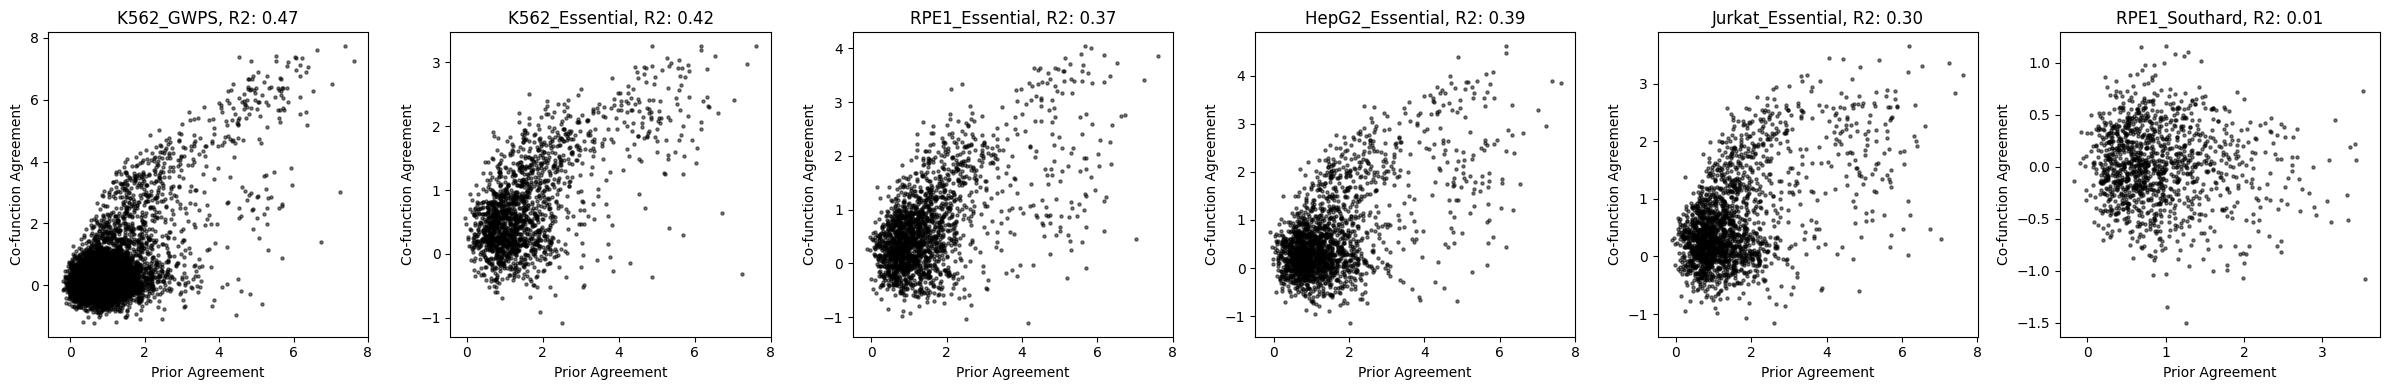

In [3]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import spearmanr
fig, ax = plt.subplots(1, len(analysis_targets), figsize=(24, 4))

prior_pert_z_scores = {}
for i, perturb_seq_name in enumerate(analysis_targets): 
    local_df = gene_level_local_metrics[perturb_seq_name].mean(axis=1)
    global_df = gene_level_global_metrics[perturb_seq_name].mean(axis=1)
    prior_pert_z_score = (global_df+local_df)/2
    joint_idx = list(set(prior_z_score.index).intersection(set(prior_pert_z_score.index)))
    tmp_prior_z = prior_z_score.loc[joint_idx]
    tmp_prior_pert_z = prior_pert_z_score.loc[joint_idx]
    
    prior_pert_z_scores[perturb_seq_name] = tmp_prior_pert_z

    ax[i].scatter(tmp_prior_z, tmp_prior_pert_z, s=5, alpha=0.5, color='black')
    #ax[i].set_title(f'Inter-prior agreement \n vs. ps-prior agreement \n {perturb_seq_name}, N={len(joint_idx)} \n Rs={spearmanr(tmp_prior_z, tmp_prior_pert_z).statistic:.2f}')    

    X = tmp_prior_z.values
    X = sm.add_constant(X)
    y = tmp_prior_pert_z.values  
    mod = sm.OLS(y, X)
    resource = mod.fit()
    ax[i].set_title(f'{perturb_seq_name}, R2: {resource.rsquared:.2f}')
    ax[i].set_xlabel('Prior Agreement')
    ax[i].set_ylabel('Co-function Agreement')
plt.tight_layout()
#plt.savefig('./figure_out/Fig.S3A.pdf')

In [4]:
import gseapy as gp

common_essential_genes = pd.read_csv("/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/CRISPRInferredCommonEssentials.csv")
# https://depmap.org/portal/data_page/?tab=allData,%20CRISPRInferredCommonEssentials.csv
common_essential_genes = common_essential_genes.map(lambda x: x.split(' ')[0])
common_essential_genes = common_essential_genes.values.flatten().tolist()

library = gp.get_library(name='KEGG_2026', organism='Human')
signaling_genes = []

for key, val in library.items():
    if 'signaling' in key.lower():
        signaling_genes += val
signaling_genes = list(set(signaling_genes))

tf_genes = pd.read_csv('/home/jhpark/page_reproducibility/04_genelevel_agreement/intermediate/infected_cells_per_guides_southard_rpe1_tf_crispra_effect_qc.csv')['guide'].tolist()
tf_genes.remove('off-target')

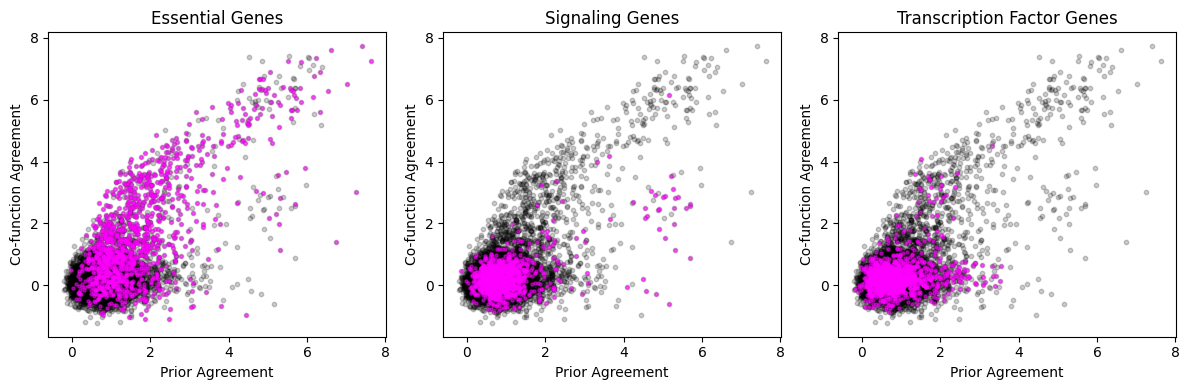

In [5]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import spearmanr
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

prior_pert_z_scores = {}
perturb_seq_name = analysis_targets[0]
local_df = gene_level_local_metrics[perturb_seq_name].mean(axis=1)
global_df = gene_level_global_metrics[perturb_seq_name].mean(axis=1)
prior_pert_z_score = (global_df+local_df)/2
joint_idx = list(set(prior_z_score.index).intersection(set(prior_pert_z_score.index)))
tmp_prior_z = prior_z_score.loc[joint_idx]
tmp_prior_pert_z = prior_pert_z_score.loc[joint_idx]

prior_pert_z_scores[perturb_seq_name] = tmp_prior_pert_z

plot_common_essential_genes = list(set(common_essential_genes).intersection(set(joint_idx)))
ax[0].scatter(tmp_prior_z, tmp_prior_pert_z, s=10, alpha=0.2, color='black')
ax[0].scatter(tmp_prior_z.loc[plot_common_essential_genes], tmp_prior_pert_z[plot_common_essential_genes], s=5, alpha=0.5, color='magenta')
ax[0].set_xlabel('Prior Agreement')
ax[0].set_ylabel('Co-function Agreement')
ax[0].set_title('Essential Genes')
plot_signaling_genes = list(set(signaling_genes).intersection(set(joint_idx)))
ax[1].scatter(tmp_prior_z, tmp_prior_pert_z, s=10, alpha=0.2, color='black')
ax[1].scatter(tmp_prior_z.loc[plot_signaling_genes], tmp_prior_pert_z[plot_signaling_genes], s=5, alpha=0.5, color='magenta')
ax[1].set_xlabel('Prior Agreement')
ax[1].set_ylabel('Co-function Agreement')
ax[1].set_title('Signaling Genes')
plot_tf_genes = list(set(tf_genes).intersection(set(joint_idx)))
ax[2].scatter(tmp_prior_z, tmp_prior_pert_z, s=10, alpha=0.2, color='black')
ax[2].scatter(tmp_prior_z.loc[plot_tf_genes], tmp_prior_pert_z[plot_tf_genes], s=5, alpha=0.5, color='magenta')
ax[2].set_xlabel('Prior Agreement')
ax[2].set_ylabel('Co-function Agreement')
ax[2].set_title('Transcription Factor Genes')
plt.tight_layout()
#plt.savefig('./figure_out/Final_Fig.S3CDE_cofunc.pdf')

mRNA

In [6]:
import pandas as pd
gene_level_local_metrics = {}
gene_level_global_metrics = {}
analysis_targets = ['K562_GWPS','K562_Essential','RPE1_Essential','HepG2_Essential','Jurkat_Essential','RPE1_Southard']
for perturb_seq_name in analysis_targets: 
    gene_level_local_metrics[perturb_seq_name] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{perturb_seq_name}_mrnaspace_gene_local_overlap_allpair.csv').set_index('gene')
    gene_level_global_metrics[perturb_seq_name] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{perturb_seq_name}_mrnaspace_gene_global_overlap_allpair.csv').set_index('gene')

prior_pert_z_scores = {}
perturb_seq_name = analysis_targets[0]
local_df = gene_level_local_metrics[perturb_seq_name].mean(axis=1)
global_df = gene_level_global_metrics[perturb_seq_name].mean(axis=1)
prior_pert_z_score = (global_df+local_df)/2
joint_idx = list(set(prior_z_score.index).intersection(set(prior_pert_z_score.index)))
tmp_prior_z = prior_z_score.loc[joint_idx]
tmp_prior_pert_z = prior_pert_z_score.loc[joint_idx]

prior_pert_z_scores[perturb_seq_name] = tmp_prior_pert_z

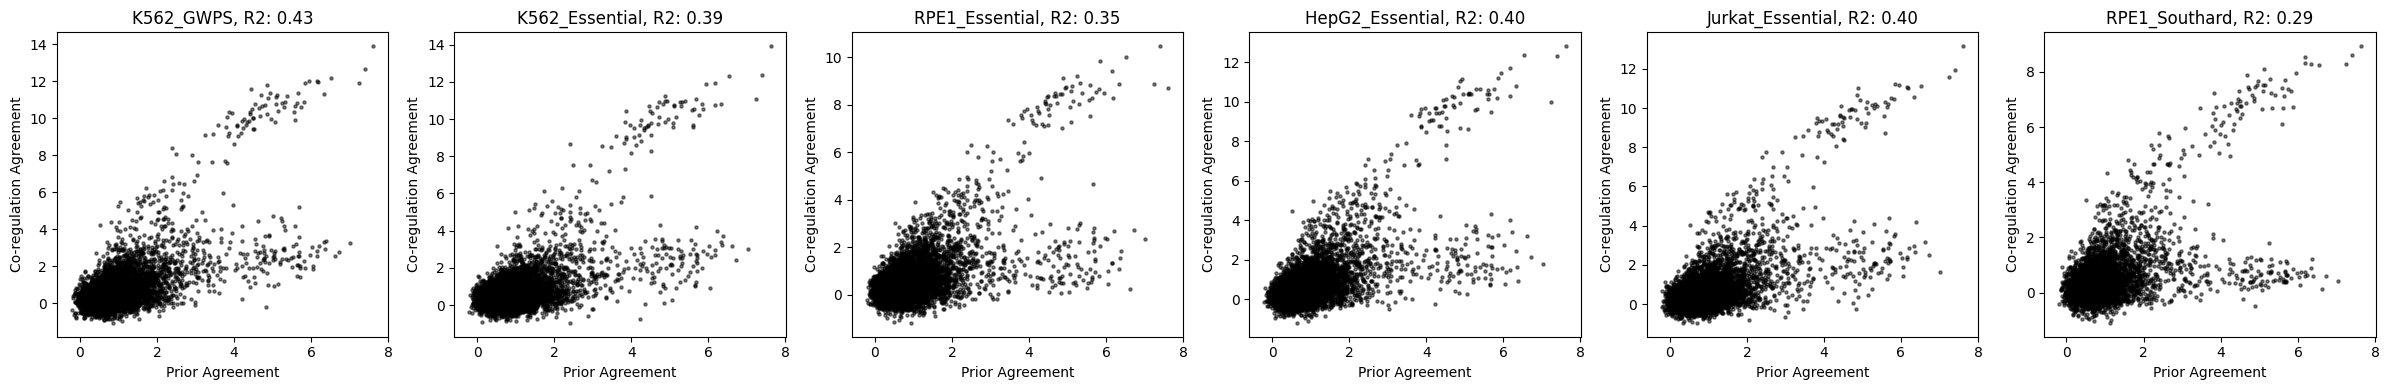

In [7]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import spearmanr
fig, ax = plt.subplots(1, len(analysis_targets), figsize=(24, 4))

prior_pert_z_scores = {}
for i, perturb_seq_name in enumerate(analysis_targets): 
    local_df = gene_level_local_metrics[perturb_seq_name].mean(axis=1)
    global_df = gene_level_global_metrics[perturb_seq_name].mean(axis=1)
    prior_pert_z_score = (global_df+local_df)/2
    joint_idx = list(set(prior_z_score.index).intersection(set(prior_pert_z_score.index)))
    tmp_prior_z = prior_z_score.loc[joint_idx]
    tmp_prior_pert_z = prior_pert_z_score.loc[joint_idx]
    
    prior_pert_z_scores[perturb_seq_name] = tmp_prior_pert_z

    ax[i].scatter(tmp_prior_z, tmp_prior_pert_z, s=5, alpha=0.5, color='black')
    #ax[i].set_title(f'Inter-prior agreement \n vs. ps-prior agreement \n {perturb_seq_name}, N={len(joint_idx)} \n Rs={spearmanr(tmp_prior_z, tmp_prior_pert_z).statistic:.2f}')    

    X = tmp_prior_z.values
    X = sm.add_constant(X)
    y = tmp_prior_pert_z.values  
    mod = sm.OLS(y, X)
    resource = mod.fit()
    ax[i].set_title(f'{perturb_seq_name}, R2: {resource.rsquared:.2f}')
    ax[i].set_xlabel('Prior Agreement')
    ax[i].set_ylabel('Co-regulation Agreement')
plt.tight_layout()
#plt.savefig('./figure_out/Fig.S3B.pdf')

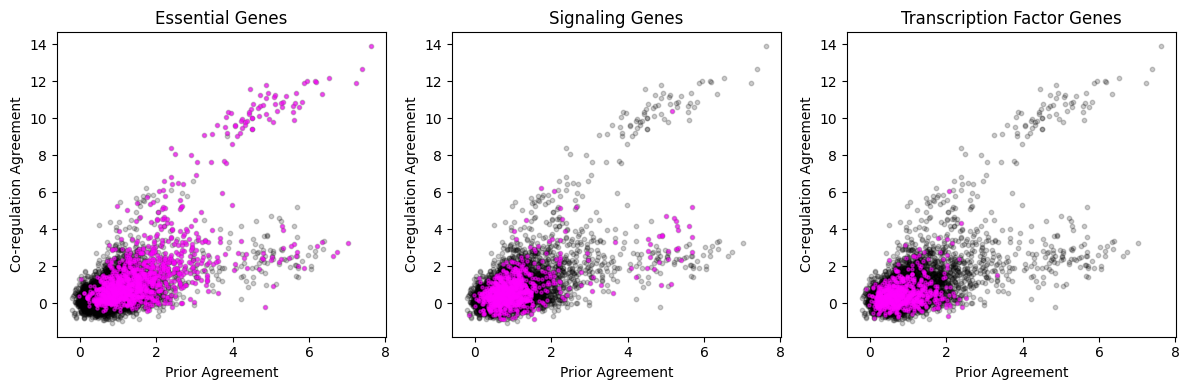

In [8]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import spearmanr
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

prior_pert_z_scores = {}
perturb_seq_name = analysis_targets[0]
local_df = gene_level_local_metrics[perturb_seq_name].mean(axis=1)
global_df = gene_level_global_metrics[perturb_seq_name].mean(axis=1)
prior_pert_z_score = (global_df+local_df)/2
joint_idx = list(set(prior_z_score.index).intersection(set(prior_pert_z_score.index)))
tmp_prior_z = prior_z_score.loc[joint_idx]
tmp_prior_pert_z = prior_pert_z_score.loc[joint_idx]

prior_pert_z_scores[perturb_seq_name] = tmp_prior_pert_z

plot_common_essential_genes = list(set(common_essential_genes).intersection(set(joint_idx)))
ax[0].scatter(tmp_prior_z, tmp_prior_pert_z, s=10, alpha=0.2, color='black')
ax[0].scatter(tmp_prior_z.loc[plot_common_essential_genes], tmp_prior_pert_z[plot_common_essential_genes], s=5, alpha=0.5, color='magenta')
ax[0].set_xlabel('Prior Agreement')
ax[0].set_ylabel('Co-regulation Agreement')
ax[0].set_title('Essential Genes')
plot_signaling_genes = list(set(signaling_genes).intersection(set(joint_idx)))
ax[1].scatter(tmp_prior_z, tmp_prior_pert_z, s=10, alpha=0.2, color='black')
ax[1].scatter(tmp_prior_z.loc[plot_signaling_genes], tmp_prior_pert_z[plot_signaling_genes], s=5, alpha=0.5, color='magenta')
ax[1].set_xlabel('Prior Agreement')
ax[1].set_ylabel('Co-regulation Agreement')
ax[1].set_title('Signaling Genes')
plot_tf_genes = list(set(tf_genes).intersection(set(joint_idx)))
ax[2].scatter(tmp_prior_z, tmp_prior_pert_z, s=10, alpha=0.2, color='black')
ax[2].scatter(tmp_prior_z.loc[plot_tf_genes], tmp_prior_pert_z[plot_tf_genes], s=5, alpha=0.5, color='magenta')
ax[2].set_xlabel('Prior Agreement')
ax[2].set_ylabel('Co-regulation Agreement')
ax[2].set_title('Transcription Factor Genes')
plt.tight_layout()
#plt.savefig('./figure_out/Final_Fig.S3CDE_coreg.pdf')